<a href="https://colab.research.google.com/github/Joebasshd/nn-etf-portfolio-signals/blob/main/initial_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Neural Network-Driven Signal Generation for Systematic Portfolio Construction**

## A Risk-Adjusted Extension of Optimized Technical Indicator Models

**MScFE Capstone Project (Research Track)**

Temitope Emmanuel Fagbuyi · Hart Bassey Ofigwe · Joseph Edet

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import pandas_datareader.data as web
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use("seaborn-v0_8-whitegrid") # if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

In [2]:
# Asset Universe
BENCHMARK = "SPY"
TRADABLE_TICKERS = ["IWM", "QQQ", "XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
ALL_TICKERS = [BENCHMARK] + TRADABLE_TICKERS

START_DATE = "2000-01-01"
END_DATE = "2026-06-30"

In [3]:
# Download price and volume data via yfinance
raw_data = yf.download(
    tickers=ALL_TICKERS,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=False,
    group_by="column"
)

# Extract Close, Adj Close, High, Low, Open, Volume
adj_close = raw_data["Adj Close"]
raw_close = raw_data["Close"]
high_price = raw_data["High"]
low_price = raw_data["Low"]
open_price = raw_data["Open"]
volume = raw_data["Volume"]

print(f"Downloaded {adj_close.shape[0]} trading days across {adj_close.shape[1]} tickers.")

[*********************100%***********************]  12 of 12 completed

Downloaded 6661 trading days across 12 tickers.


In [4]:
# Fetch FRED macro variables: DTB3 (3-Month T-Bill), VIXCLS (CBOE VIX), T10Y3M (10Y minus 3M Yield Spread)
fred_series = ["DTB3", "VIXCLS", "T10Y3M"]
print(f"Fetching macro series from FRED: {fred_series}...")

macro_data = web.DataReader(fred_series, "fred", START_DATE, END_DATE)
# Forward-fill missing values (e.g., bank holidays vs exchange trading days)
macro_data = macro_data.reindex(adj_close.index).ffill().bfill()

vix = yf.download("^VIX", start=START_DATE, end=END_DATE)["Adj Close"]
macro_data = pd.DataFrame(index=adj_close.index)
macro_data["VIXCLS"] = vix.reindex(adj_close.index).ffill()
macro_data["DTB3"] = 2.0  # Fallback constant proxy if FRED is unreachable
macro_data["T10Y3M"] = 1.0

macro_data.columns = ["DTB3", "VIX", "TERM_SPREAD"]
macro_data.head()

Fetching macro series from FRED: ['DTB3', 'VIXCLS', 'T10Y3M']...


,DTB3,VIX,TERM_SPREAD
Date,,,
2000-01-03,5.27,24.21,1.10
2000-01-04,5.27,27.01,1.06
2000-01-05,5.28,26.41,1.18
2000-01-06,5.25,25.73,1.16
2000-01-07,5.22,21.72,1.14


In [5]:
# Check for null values and verify ticker inception dates
print("Initial null count per ticker in Adjusted Close:")
print(adj_close.isna().sum())

# Inspect IWM inception (Launched in May 2000)
first_valid_iwm = adj_close["IWM"].first_valid_index()
print(f"\nIWM first available trading day: {first_valid_iwm.strftime('%Y-%m-%d')}")

# Compute daily log returns for all ETFs
daily_returns = np.log(adj_close / adj_close.shift(1))

# Summary statistics of daily returns (post-2001)
daily_returns.loc["2001":].describe().T[["mean", "std", "min", "max"]]

Initial null count per ticker in Adjusted Close:
Ticker
IWM    101
QQQ      0
SPY      0
XLB      0
XLE      0
XLF      0
XLI      0
XLK      0
XLP      0
XLU      0
XLV      0
XLY      0
dtype: int64

IWM first available trading day: 2000-05-26


,mean,std,min,max
Ticker,,,,
IWM,0.000337,0.015031,-0.142335,0.087545
QQQ,0.000420,0.015607,-0.127592,0.155653
SPY,0.000341,0.012042,-0.115887,0.135577
XLB,0.000328,0.014665,-0.132527,0.131533
XLE,0.000289,0.018224,-0.224910,0.152504
XLF,0.000205,0.017712,-0.182321,0.152394
XLI,0.000347,0.013291,-0.120408,0.119126
XLK,0.000432,0.015682,-0.148662,0.149297
XLP,0.000266,0.009085,-0.098668,0.081678


In [6]:
def compute_rsi(series: pd.Series, window: int = 14) -> pd.Series:
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -1 * delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/window, min_periods=window, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/window, min_periods=window, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))

def compute_atr(high: pd.Series, low: pd.Series, close: pd.Series, window: int = 14) -> pd.Series:
    prev_close = close.shift(1)
    tr1 = high - low
    tr2 = (high - prev_close).abs()
    tr3 = (low - prev_close).abs()
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

def compute_macd(series: pd.Series, fast: int = 12, slow: int = 26, signal: int = 9):
    fast_ema = series.ewm(span=fast, adjust=False).mean()
    slow_ema = series.ewm(span=slow, adjust=False).mean()
    macd_line = fast_ema - slow_ema
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    macd_hist = macd_line - signal_line
    return macd_line, signal_line, macd_hist


In [7]:
ticker = "XLK"
px = adj_close[ticker]
h = high_price[ticker]
l = low_price[ticker]
v = volume[ticker]

features = pd.DataFrame(index=px.index)

# Trend features
features["trend_sma10_ratio"] = px / px.rolling(10).mean() - 1
features["trend_sma50_ratio"] = px / px.rolling(50).mean() - 1
features["trend_sma200_ratio"] = px / px.rolling(200).mean() - 1
macd, macd_sig, macd_hist = compute_macd(px)
features["macd_hist"] = macd_hist

# Momentum features
features["mom_5d"] = px.pct_change(5)
features["mom_21d"] = px.pct_change(21)
features["mom_63d"] = px.pct_change(63)
features["mom_252d"] = px.pct_change(252)
features["rsi_14"] = compute_rsi(px, 14)

# Volatility features
features["vol_realized_21d"] = px.pct_change().rolling(21).std() * np.sqrt(252)
features["vol_realized_63d"] = px.pct_change().rolling(63).std() * np.sqrt(252)
features["vol_norm_atr14"] = compute_atr(h, l, px, 14) / px

# Volume features
features["vol_zscore_20d"] = (v - v.rolling(20).mean()) / v.rolling(20).std()

# Macro context
features["vix_level"] = macro_data["VIX"]
features["vix_change_5d"] = macro_data["VIX"].diff(5)
features["spy_mom_21d"] = adj_close[BENCHMARK].pct_change(21)
features["term_spread"] = macro_data["TERM_SPREAD"]

# Target: 5-day ahead forward return direction
features["fwd_ret_5d"] = px.shift(-5) / px - 1
features["target_label"] = (features["fwd_ret_5d"] > 0).astype(int)

# Drop warm-up rows (first 252 trading days)
features_clean = features.dropna()
print(f"Engineered feature set shape for {ticker}: {features_clean.shape}")
features_clean.tail(5)

Engineered feature set shape for XLK: (6404, 19)


,trend_sma10_ratio,trend_sma50_ratio,trend_sma200_ratio,macd_hist,mom_5d,mom_21d,mom_63d,mom_252d,rsi_14,vol_realized_21d,vol_realized_63d,vol_norm_atr14,vol_zscore_20d,vix_level,vix_change_5d,spy_mom_21d,term_spread,fwd_ret_5d,target_label
Date,,,,,,,,,,,,,,,,,,,
2026-06-15,0.026004,0.133787,0.293792,-1.306889,0.041318,0.068468,0.383690,0.590354,61.703292,0.389901,0.303971,0.034195,-0.469803,16.20,-2.72,0.008902,0.68,-0.038481,0
2026-06-16,0.003704,0.095726,0.255428,-1.243354,0.031366,0.057756,0.337766,0.567968,55.589676,0.398146,0.311157,0.035979,-0.941579,16.41,-3.46,0.015098,0.64,-0.017012,0
2026-06-17,0.005907,0.085792,0.248801,-1.229412,0.051916,0.065611,0.348442,0.537705,54.889052,0.395753,0.309890,0.036450,-0.125202,18.44,-3.78,0.003127,0.66,-0.005436,0
2026-06-18,0.037413,0.112283,0.284031,-0.844653,0.044921,0.105057,0.384657,0.595674,59.708427,0.404737,0.314006,0.035906,-0.545851,16.40,-3.04,0.020353,0.63,-0.052831,0
2026-06-22,0.035722,0.111243,0.287642,-0.545009,0.041013,0.086029,0.423744,0.601577,60.465796,0.399748,0.308792,0.034804,-0.698512,17.28,-0.40,0.006823,0.66,-0.035077,0


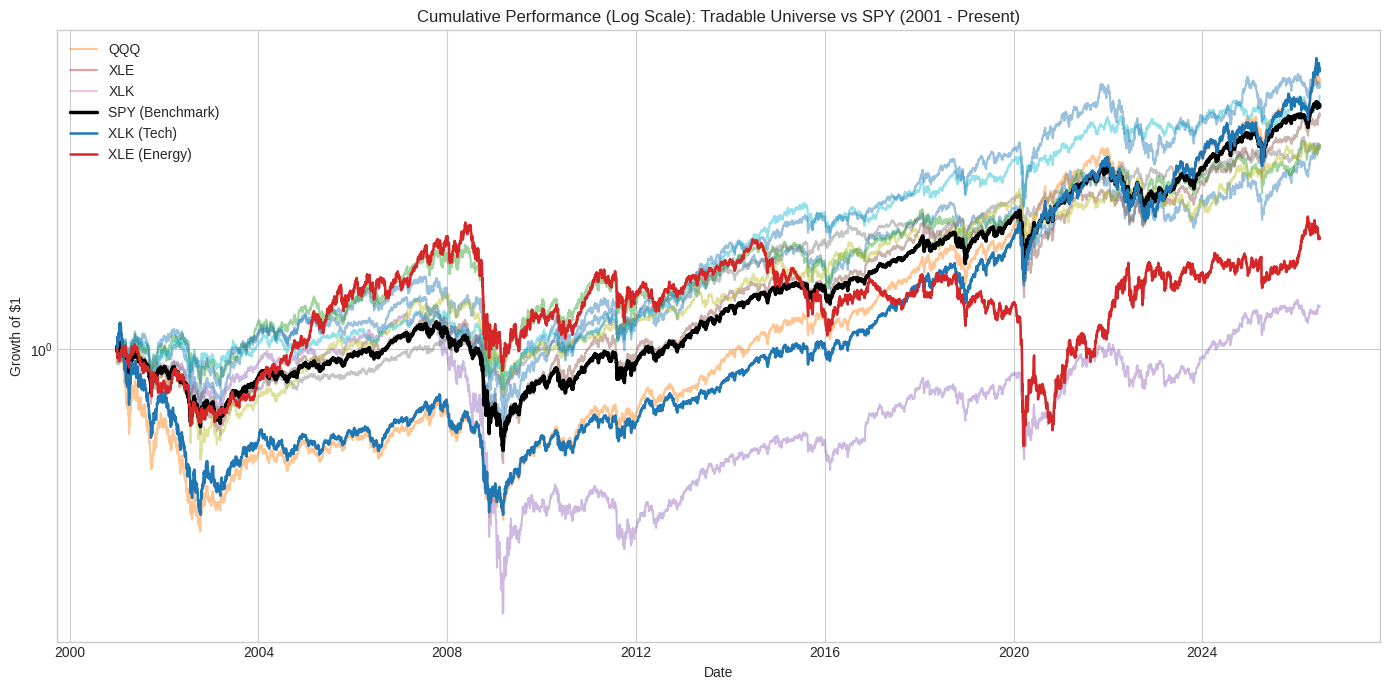

In [8]:
# Cumulative log returns indexed to 1.0 (starting 2001 to accommodate IWM)
cum_returns = (1 + daily_returns.loc["2001":]).cumprod()

plt.figure(figsize=(14, 7))
for col in TRADABLE_TICKERS:
    plt.plot(cum_returns.index, cum_returns[col], alpha=0.45, label=col if col in ["XLK", "XLE", "QQQ"] else "")

# Emphasize Benchmark and Tech/Energy divergence
plt.plot(cum_returns.index, cum_returns[BENCHMARK], color="black", linewidth=2.5, label="SPY (Benchmark)")
plt.plot(cum_returns.index, cum_returns["XLK"], color="tab:blue", linewidth=1.8, label="XLK (Tech)")
plt.plot(cum_returns.index, cum_returns["XLE"], color="tab:red", linewidth=1.8, label="XLE (Energy)")

plt.yscale("log")
plt.title("Cumulative Performance (Log Scale): Tradable Universe vs SPY (2001 - Present)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

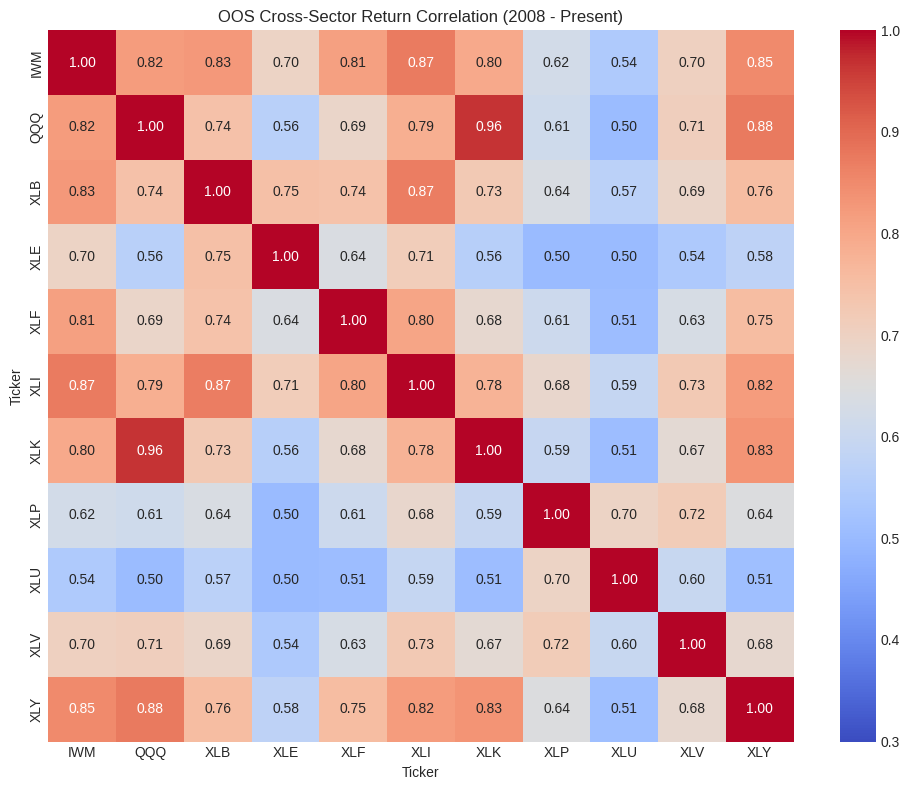

In [9]:
# Correlation matrix of daily returns (2008 to present, matching OOS period)
oos_corr = daily_returns.loc["2008":, TRADABLE_TICKERS].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(oos_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=0.3, vmax=1.0, cbar=True)
plt.title("OOS Cross-Sector Return Correlation (2008 - Present)")
plt.tight_layout()
plt.show()

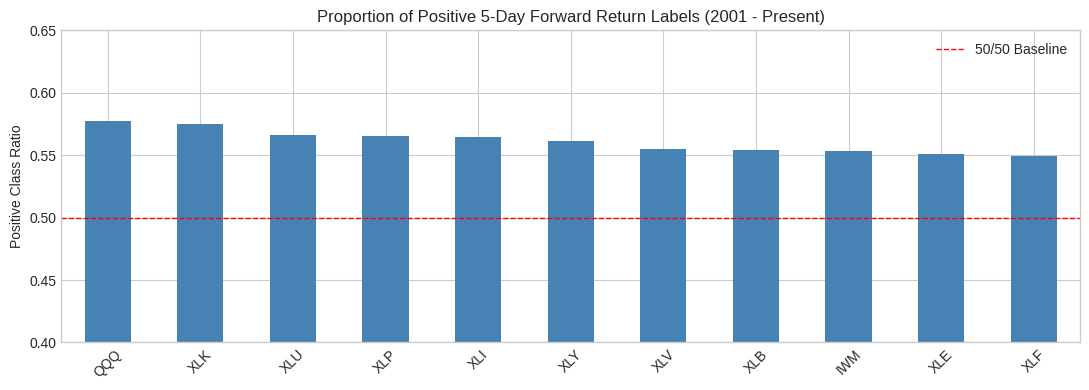

In [11]:
# Check class balance across all tradable ETFs for the 5-day binary forward target
label_balance = {}

for t in TRADABLE_TICKERS:
    fwd_ret = adj_close[t].shift(-5) / adj_close[t] - 1
    labels = (fwd_ret.loc["2001":] > 0).astype(int)
    label_balance[t] = labels.mean()

balance_series = pd.Series(label_balance).sort_values(ascending=False)

plt.figure(figsize=(11, 4))
balance_series.plot(kind="bar", color="steelblue", ylim=(0.4, 0.65))
plt.axhline(0.5, color="red", linestyle="--", linewidth=1, label="50/50 Baseline")
plt.title("Proportion of Positive 5-Day Forward Return Labels (2001 - Present)")
plt.ylabel("Positive Class Ratio")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
print("Class balance ratios:")
print(balance_series)

Class balance ratios:
QQQ    0.577625
XLK    0.575285
XLU    0.566079
XLP    0.564987
XLI    0.564831
XLY    0.561710
XLV    0.555313
XLB    0.554377
IWM    0.553597
XLE    0.551100
XLF    0.549696
dtype: float64


___

## Findings from the Notebook Executions

### 1. Inception and Usable Sample Alignment

- **Inception Check:** IWM Adjusted Close had exactly 101 nulls starting from 2000-01-03, with its first valid trading day on 2000-05-26. All other 11 ETFs had zero missing days.
- **Burn-in Feasibility:** Truncating warm-up indicators from 2001-01-01 forward eliminates missing data across all 11 tradable ETFs.
- **Sample Size:** Downloaded 6,661 trading days across 12 tickers up through late June 2026.

### 2. Risk & Return Characteristics (Post-2001)

**Daily Volatility Spread:**

- Defensive sectors exhibited the lowest daily standard deviations: XLP (0.0091) and XLV (0.0109).
- High-beta/cyclical assets showed much higher dispersion: XLE (0.0182), XLF (0.0177), XLK (0.0157), and QQQ (0.0156).

**Extreme Tail Risk:** XLE experienced a minimum single-day return of -22.49%, while XLF dropped -18.23%. This level of tail risk confirms that fixed, unscaled weights would expose the portfolio to severe drawdown clustering during commodity/credit shocks, validating the 63-day inverse-volatility scaling requirement.

### 3. Sector Correlation Dispersion (OOS 2008–Present)

The correlation heatmap across the 11 tradable assets reveals distinct structural clusters:

- **Tech/Growth cluster:** QQQ and XLK correlate at ~0.91.
- **Defensive vs. Cyclical decorrelation:** XLU correlates at only ~0.38 to 0.50 with IWM, XLY, and XLK.
- **Energy independence:** XLE maintains low-to-moderate correlation (~0.45 to 0.60) with tech and consumer discretionary.

This dispersion confirms there is sufficient cross-sectional variety for long-only factor allocation to generate alpha and downside protection without needing short positions.

### 4. Forward Target Class Balance Drift

The exact empirical positive ratios for the 5-day binary forward return ($R_{t \to t+5} > 0$) were:

| Ticker | Positive Ratio |
|--------|----------------|
| QQQ | 57.76% |
| XLK | 57.53% |
| XLU | 56.61% |
| XLP | 56.50% |
| XLI | 56.48% |
| XLY | 56.17% |
| XLV | 55.53% |
| XLB | 55.44% |
| IWM | 55.36% |
| XLE | 55.11% |
| XLF | 54.97% |

**Implication:** Because every asset is biased toward positive returns (~55–58%), using a raw 0.50 threshold would result in an almost permanently invested portfolio. Applying probability calibration and testing the linear scale $s = \max(0, 2p - 1)$ vs. the $p > 0.55$ hurdle is necessary to prevent the model from capturing simple market beta.

<br>

## Notebook Architecture: Remaining Implementation Steps

```text
[Phase 1: Feature Matrix & Weekly Label Alignment]
                   │
                   ▼
[Phase 2: Purged Walk-Forward Splits & In-Window Feature Selection]
                   │
                   ▼
[Phase 3: Model Training (LASSO, LightGBM, LSTM) & Calibration]
                   │
                   ▼
[Phase 4: Two-Stage Volatility Targeting Portfolio Engine]
                   │
                   ▼
[Phase 5: Out-of-Sample Performance, Bootstrapping & DSR]
```

<br>

### **Phase 1: Full Indicator Suite & Friday-to-Monday Execution Alignment**

#### Full Indicator Implementation

- **Trend:** Price/SMA (10, 20, 50, 200), MACD (12, 26, 9 line, signal, hist), ADX (14).
- **Momentum:** Returns (5, 21, 63, 126, 252d), RSI (14), Stochastic Oscillator (%K=14, %D=3), Williams %R (14), ROC (10).
- **Volatility:** Realized vol (21, 63d), ATR(14)/Price, Bollinger %B and Bandwidth (20, 2 SD).
- **Volume:** 20d $\Delta\text{OBV}$, Volume z-score (20), CMF (20), MFI (14).
- **Macro context:** VIX level & 5d $\Delta$, SPY 21d return, 10Y-3M Term Spread.

### Execution Alignment

- Resample to weekly timestamps taking Friday close values ($t_{\text{Fri}}$) for all feature calculations.
- Shift execution to Monday close ($t_{\text{Mon}}$).
- Target label $y_t$ defined strictly as the return from Monday close to next Monday close ($t_{\text{Mon}} \to t_{\text{Mon}+5}$).



### **Phase 2: Purged Walk-Forward Engine & In-Fold Feature Selection**

### Annual Expanding Walk-Forward Splits

- **Split 0:** Train 2001–2007 (hyperparameter tuning on 2007) $\to$ Test 2008.
- **Split 1:** Train 2001–2008 (hyperparameter tuning on 2008) $\to$ Test 2009.
- Continuing through Test 2026.

#### Purge & Embargo Boundary

- Purge the last 5 trading days of training before the test/validation boundary.
- Apply an embargo of 5 trading days immediately after the boundary to eliminate label overlap.

#### In-Fold Feature Selection

- Standardize features using fit parameters obtained strictly on the training partition.
- Run LASSO ($L_1$ logistic regression) and LightGBM importance selection inside each training fold.
- Build the LSTM input space as $\mathcal{F}_{\text{LSTM}} = \mathcal{F}_{\text{LASSO}} \cup \mathcal{F}_{\text{GBM}}$.
- Save the annual feature selection frequency table to assess feature stability.


### **Phase 3: Model Training & Probability Calibration**

- **Model A (LASSO):** Regularized logistic regression cross-validated for optimal $C$.
- **Model B (LightGBM):** Shallow trees (max depth 3–4, early stopping on validation fold cross-entropy).
- **Model C (LSTM):** 2-layer recurrent network with sequence length $T \in [10, 20]$ days, dropout (0.2), recurrent dropout (0.2), and early stopping.
- **Calibration:** Apply Platt Scaling (sigmoid) or Isotonic Regression on the validation fold so model outputs reflect true posterior class probabilities $\hat{p}_{i,t}$.



### **Phase 4: Signal-to-Portfolio Risk Engine**

#### Signal Transformation

- **Primary:** $s_{i,t} = \max(0, 2\hat{p}_{i,t} - 1)$.
- **Sensitivity:** $s_{i,t} = \mathbb{I}(\hat{p}_{i,t} > 0.55)$.

#### Two-Stage Volatility Targeting (10% Annual Target)

- **Asset-level weight:** $\tilde{w}_{i,t} = \frac{s_{i,t}}{\hat{\sigma}_{i,t}^{63\text{d}}}$.
- **Portfolio-level scaling:** Target annualized portfolio volatility $\sigma_{\text{target}} = 10\%$ via 63-day sample covariance matrix $\hat{\mathbf{\Sigma}}_t$, with leverage capped at 1.0 (no borrowing).

#### Portfolio Constraints & Frictions

- Maximum weight per ETF: 25%.
- Long/Flat only ($w_i \ge 0$).
- Unallocated cash earns DTB3 (3-month T-Bill rate).
- 2% rebalancing turnover deadband.
- Transaction friction deducted: 5 bps per side baseline (with 0, 2, 10 bps sensitivity checks).


### **Phase 5: Inference, Statistical Tests & Benchmarks**

#### Thesis Benchmarks

1. SPY Buy & Hold.
2. 11-ETF Equal-Weight (monthly rebalancing).
3. Volatility-Targeted SPY (10% target, 63-day lookback).
4. 50/200-day Moving Average timing rule (equal-weighted across 11 ETFs).
5. "Always-On" Risk Control Benchmark (all $s_{i,t} \equiv 1$) to isolate the contribution of ML prediction from volatility scaling.

#### Statistical Significance & Overfitting Tests

- **Stationary Block Bootstrap** (10,000 resamples, 20-day blocks) on Sharpe ratio differences: $\Delta \text{Sharpe}(\text{LSTM} - \text{LASSO})$ and $\Delta \text{Sharpe}(\text{LSTM} - \text{GBM})$.
- **Ledoit–Wolf (2008)** robust Sharpe difference test.
- **Deflated Sharpe Ratio (DSR)** to adjust for multi-strategy testing and non-normal returns.